# Step 28: Main experiments for the supervisor's review (24 conversations)
Gradient Boosting on every input, under the new protocols: speaker-independent 6-fold CV, leave-one-language-out (train on 2 languages, test on the 3rd), within vs cross language with the same training size, and a held-out test set used once. Covers review items E2, E3, E5, E6 and problems 1-5.
*This notebook only loads the saved results of `src/28_review_experiments.py` (reports/*.csv); it does not train anything.*

**In short** (what this notebook shows)

- **What:** The main experiments for the supervisor's review with Gradient Boosting: every input, train on 2 languages and test the 3rd, within vs cross language with the same training size, held-out test used once, statistics, baselines, face-confound tests.
- **Needs the NoXi data?** No: it only loads reports/*.csv, runs in seconds.
- **Result / use:** Voice 0.654, face 0.361, fusion + context 0.767 (held-out test 0.839, drop on a new language 6%). Show this to ma'am.

### Dataset
**NoXi** (NOvice eXpert Interaction) - expert-novice conversations with continuous engagement labels.
- Paper: A. Cafaro et al., ACM ICMI 2017 (https://doi.org/10.1145/3136755.3136780); challenge page: https://multimediate.perceptualui.org
- Used here: **24 conversations** (8 English, 8 French, 8 German; 48 people; 48,486 one-second windows) with eGeMAPS voice, OpenFace 2.0 face features and the pretrained w2v-BERT 2.0 / VideoMAE embeddings shipped with the corpus.
- Licence: NoXi is available for research under an End-User Licence Agreement. The data is **not included** and must not be shared.

Go to the project folder.

In [2]:
import os
if os.getcwd().endswith("notebooks"):
    os.chdir("..")          # work from the project folder

**Imports.**

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 220)

**2.1 All inputs.** CV CCC (new speakers), train on 2 languages -> 3rd, within vs cross with matched training size, and the drop in absolute and relative terms.

In [4]:
a = pd.read_csv('reports/gb_all_inputs.csv')
print(a[['input', 'features', 'cv_ccc', 'cv_std', 'lolo_mean', 'within_matched', 'cross_matched', 'drop_abs', 'drop_pct', 'dev_ccc']].round(3).to_string(index=False))

                                  input  features  cv_ccc  cv_std  lolo_mean  within_matched  cross_matched  drop_abs  drop_pct  dev_ccc
                                  voice        88   0.654   0.115      0.620           0.571          0.532     0.039     6.773    0.632
                         face (all 709)       709   0.361   0.142      0.326           0.272          0.229     0.043    15.858    0.306
                face (AU+gaze+pose, 49)        49   0.373   0.113      0.356           0.322          0.249     0.073    22.603    0.346
     face (all 709), speaker-normalised       709   0.239   0.150      0.261           0.214          0.122     0.091    42.698    0.203
face (AU+gaze+pose), speaker-normalised        49   0.215   0.156      0.227           0.206          0.111     0.095    46.116    0.149
                           voice + face       797   0.645   0.099      0.599           0.468          0.498    -0.030    -6.385    0.619
            voice + face (AU+gaze+pose)  

**Chart:** CV CCC and train-2-languages -> 3rd for every input.

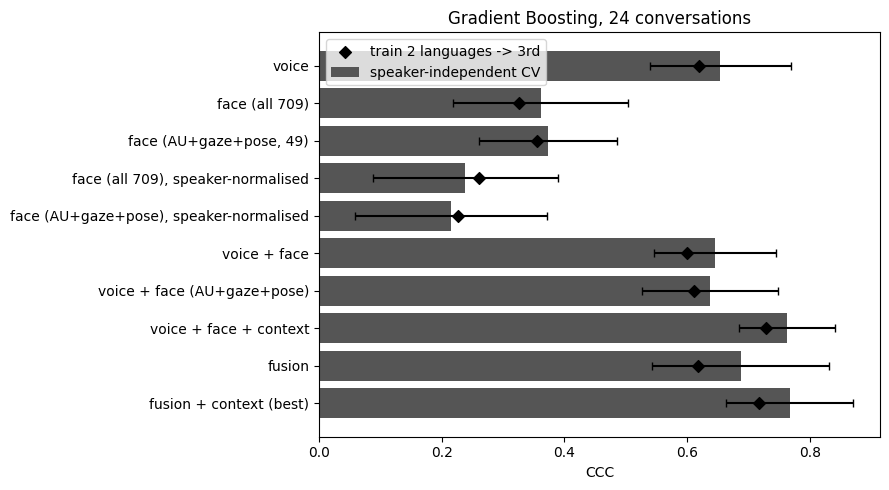

In [5]:
b = a.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(b['input'], b['cv_ccc'], xerr=b['cv_std'], color='#555555', capsize=3, label='speaker-independent CV')
ax.scatter(b['lolo_mean'], b['input'], color='black', marker='D', zorder=3, label='train 2 languages -> 3rd')
ax.set_xlabel('CCC'); ax.legend(); ax.set_title('Gradient Boosting, 24 conversations'); plt.tight_layout(); plt.show()

**2.2 Leave-one-language-out:** CCC on each unseen language.

In [6]:
print(pd.read_csv('reports/gb_lolo.csv').round(3).to_string(index=False))

                                  input  test_English  test_French  test_German  mean
                                  voice         0.471        0.641        0.747 0.620
                         face (all 709)         0.143        0.421        0.414 0.326
                face (AU+gaze+pose, 49)         0.186        0.421        0.461 0.356
     face (all 709), speaker-normalised         0.194        0.247        0.343 0.261
face (AU+gaze+pose), speaker-normalised         0.179        0.211        0.289 0.227
                           voice + face         0.490        0.663        0.645 0.599
            voice + face (AU+gaze+pose)         0.456        0.674        0.702 0.611
                 voice + face + context         0.601        0.771        0.815 0.729
                                 fusion         0.463        0.689        0.700 0.617
                fusion + context (best)         0.623        0.779        0.746 0.716


**2.3 Held-out test set** (sessions 007, 009, 062, 063, 072, 073), used once. The model was chosen on the other 18 sessions.

In [7]:
print(pd.read_csv('reports/heldout_test_once.csv').round(3).to_string(index=False))

                  input  chosen_on_dev  test_ccc  test_007  test_009  test_062  test_063  test_072  test_073
           voice + face          False     0.714     0.763     0.367     0.392     0.738     0.836     0.814
 voice + face + context          False     0.779     0.809     0.482     0.456     0.812     0.906     0.874
fusion + context (best)           True     0.839     0.877     0.453     0.620     0.817     0.928     0.813


**2.4 Statistics over the 24 sessions:** bootstrap 95% CI, Wilcoxon test, Holm correction.

In [8]:
print(pd.read_csv('reports/session_statistics.csv').round(4).to_string(index=False))

                                       comparison  mean_diff  ci_low  ci_high better  p_wilcoxon  p_holm
          fusion + context (best) vs voice + face     0.1012  0.0545   0.1438  21/24      0.0004  0.0011
           voice + face + context vs voice + face     0.1201  0.0956   0.1446  24/24      0.0000  0.0000
fusion + context (best) vs voice + face + context    -0.0188 -0.0562   0.0177  12/24      0.5457  1.0000
                          voice vs face (all 709)     0.2688  0.2002   0.3388  23/24      0.0000  0.0000
        face (AU+gaze+pose, 49) vs face (all 709)     0.0046 -0.0563   0.0626  11/24      0.8774  1.0000


**2.5 Baselines (E5).** Training mean gives CCC 0. Session mean and persistence use the true labels of the test data, so they are references, not usable models. An inter-rater ceiling cannot be computed because NoXi gives one combined label per person.

In [9]:
print(pd.read_csv('reports/baselines.csv').round(3).to_string(index=False))

                                                model  cv_ccc  cv_std  median_session_ccc
                                        training mean   0.000   0.000               0.000
           session mean (uses test labels, reference)   0.105   0.069               0.000
persistence: previous second (uses labels, reference)   0.968   0.002               0.965


**2.6 Face detection per recording site / language (E6c).**

In [10]:
print(pd.read_csv('reports/site_face_detection.csv').round(3).to_string(index=False))

language  windows  mean_engagement  face_confidence  face_success_rate
 English    15074            0.541            0.957              0.991
  French    19060            0.601            0.968              0.993
  German    14352            0.578            0.966              0.995
